It originates from a 2014 study by Himes et al. published in PLOS ONE, which investigated how glucocorticoids (steroids) function to reduce cellular inflammation in asthma patients

The airway dataset is a classic, high-throughput transcriptomics dataset widely

experiment on human smooth muscle cells treated with dexamethasone

It provides the raw number of sequencing reads mapped to every specific Ensembl gene ID

In [ ]:
import pandas as pd
from statsmodels.stats.multitest import multipletests
from scipy import stats


In [181]:
dex = pd.read_csv('../Datasets/airway_merged_data_cleaned.csv')
dex

,gene_id,dex,cell_line,count
0,E000003,treated,S08,448
1,E000003,treated,S09,408
2,E000003,treated,S12,1047
3,E000003,treated,S13,572
4,E000003,untreated,S16,679
...,...,...,...,...
203219,E273488,treated,S13,14
203220,E273488,untreated,S16,7
203221,E273488,untreated,S17,8
203222,E273488,untreated,S20,8


In [98]:
dex.head(8)

,gene_id,dex,cell_line,count
0,E000003,treated,S08,448
1,E000003,treated,S09,408
2,E000003,treated,S12,1047
3,E000003,treated,S13,572
4,E000003,untreated,S16,679
5,E000003,untreated,S17,873
6,E000003,untreated,S20,1138
7,E000003,untreated,S21,770


In [99]:
dex.tail(8)

,gene_id,dex,cell_line,count
203216,E273488,treated,S08,5
203217,E273488,treated,S09,3
203218,E273488,treated,S12,16
203219,E273488,treated,S13,14
203220,E273488,untreated,S16,7
203221,E273488,untreated,S17,8
203222,E273488,untreated,S20,8
203223,E273488,untreated,S21,11


In [90]:
dex['gene_id'].value_counts()


gene_id
E000003    8
E225083    8
E225077    8
E225075    8
E225071    8
          ..
E153933    8
E153930    8
E153922    8
E153914    8
E273488    8
Name: count, Length: 25403, dtype: int64

In [84]:
print(dex['sample_id'].describe())
print(dex['sample_id'].value_counts())

count     203224
unique         8
top          S08
freq       25403
Name: sample_id, dtype: object
sample_id
S08    25403
S09    25403
S12    25403
S13    25403
S16    25403
S17    25403
S20    25403
S21    25403
Name: count, dtype: int64


In [93]:
print(dex['dex'].value_counts())

dex
treated      101612
untreated    101612
Name: count, dtype: int64


In [122]:
# Group the data into genes
# Each gene has up to a maximum of 8 samples, 4 treated and 4 untreated.
# We will perform a t-test for each gene to see if there is a significant difference in expression between treated and untreated samples.
genes = dex.groupby('gene_id')

# create a dictionary to store the raw p-values from the t-tests for each gene
results = {'gene_id': [], 'p_raw': []}


# for each gene, perform a t-test to compare the means of the treated and untreated groups
for gene_id, gene in genes:

    # get the counts for the (up to) four treated and the (up to) four untreated cell lines
    trt_counts = gene[gene['dex'] == 'treated']['count'].values
    untrt_counts = gene[gene['dex'] == 'untreated']['count'].values

    # perform a t-test to compare the means of the treated and untreated groups
    test = stats.ttest_ind(trt_counts, untrt_counts)

    # store the gene_id and raw p-value from the t-test in the results dictionary
    results['gene_id'].append(gene_id)
    results['p_raw'].append(test.pvalue)

# convert the results dictionary to a pandas DataFrame for easier analysis
results = pd.DataFrame(results)


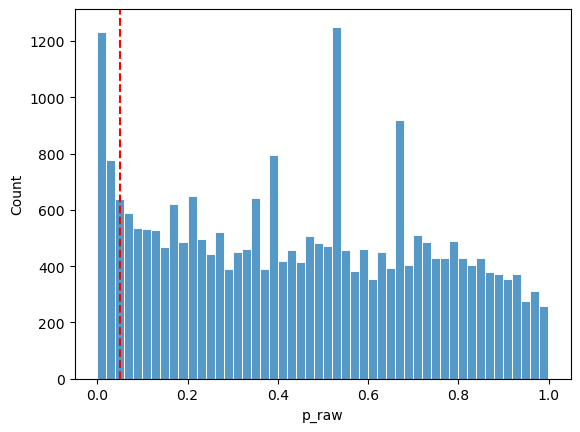

In [169]:
ax = sns.histplot(results['p_raw'], bins=50, edgecolor='white');
ax.axvline(0.05, color='red', linestyle='--');

In [143]:
len(results[results['p_raw'] < 0.05])

2360

In [145]:
results['p_bh'] = multipletests(results['p_raw'], method='fdr_bh')[1]
results['p_bonferroni'] = multipletests(results['p_raw'], method='bonferroni')[1]

print(len(results[results['p_bh'] < 0.05]))
print(len(results[results['p_bonferroni'] < 0.05]))

18
3


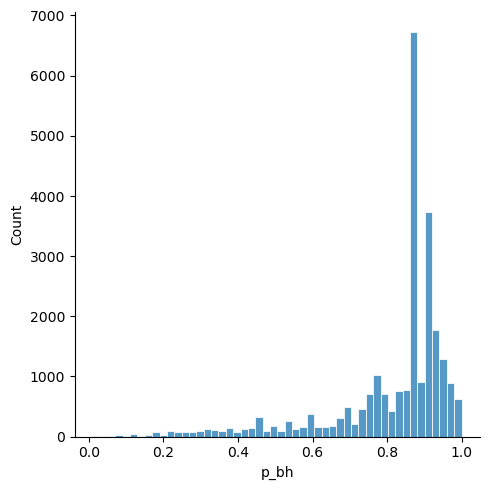

In [170]:
sns.displot(results['p_bh'], bins=50, edgecolor='white');

In [146]:
results.query('p_bh < 0.05').sort_values('p_bh')

,gene_id,p_raw,p_adjusted,p_bh,p_bonferroni
2157,E100784,9.055651e-07,0.011502,0.011502,0.023004
4729,E122877,5.165270e-07,0.011502,0.011502,0.013121
2798,E105516,1.604797e-06,0.013589,0.013589,0.040767
24138,E267683,6.219662e-06,0.039107,0.039107,0.157998
12269,E178695,7.697331e-06,0.039107,0.039107,0.195535
20803,E247311,1.488572e-05,0.043028,0.043028,0.378142
8792,E157214,1.483537e-05,0.043028,0.043028,0.376863
291,E013297,1.524426e-05,0.043028,0.043028,0.387250
2462,E102984,1.028247e-05,0.043028,0.043028,0.261206
22609,E259298,2.853776e-05,0.043326,0.043326,0.724945


In [171]:
log2fc = []

# for each gene, perform a t-test to compare the means of the treated and untreated groups
for gene_id, gene in genes:

    # get the counts for the (up to) four treated and the (up to) four untreated cell lines
    trt_counts = gene[gene['dex'] == 'treated']['count'].values
    untrt_counts = gene[gene['dex'] == 'untreated']['count'].values


    # Calculate a log2 mean fold change
    mean_trt = trt_counts.mean()
    mean_untrt = untrt_counts.mean()
    log2fc.append(np.log2((mean_trt) / (mean_untrt)))

results['log2fc'] = log2fc
results['significant'] = results['p_bh'] < 0.05
results['significant'] = results['significant'].replace({True: 'yes', False: 'no'})
results['-log10_p_raw'] = -np.log10(results['p_raw'])
results

,gene_id,p_raw,p_adjusted,p_bh,p_bonferroni,log2fc,significant,=log10_p,-log10_p,-log10_p_raw
0,E000003,0.214303,0.785119,0.785119,1.0,-0.483344,no,0.105065,0.105065,0.668972
1,E000419,0.825258,0.937694,0.937694,1.0,0.064070,no,0.027939,0.027939,0.083410
2,E000457,0.661775,0.901274,0.901274,1.0,-0.098404,no,0.045143,0.045143,0.179290
3,E000460,0.380506,0.864013,0.864013,1.0,-0.253975,no,0.063479,0.063479,0.419638
4,E000971,0.482998,0.873998,0.873998,1.0,0.337900,no,0.058490,0.058490,0.316055
...,...,...,...,...,...,...,...,...,...,...
25398,E273477,0.412773,0.873998,0.873998,1.0,0.415037,no,0.058490,0.058490,0.384289
25399,E273483,0.633334,0.901274,0.901274,1.0,0.415037,no,0.045143,0.045143,0.198367
25400,E273486,0.732533,0.914192,0.914192,1.0,-0.195551,no,0.038963,0.038963,0.135173
25401,E273487,0.029314,0.456095,0.456095,1.0,0.798366,no,0.340944,0.340944,1.532921


In [240]:
ax = sns.scatterplot(
    data=results,
    x='log2fc',
    y='-log10_p_raw',
    hue='significant',
    palette={'yes': 'crimson', 'no': 'darkgray'},
    alpha=0.6,
    edgecolor=None,
    s=15
)

ax.set_xlabel('$log_2$ fold change (treated / untreated)', fontsize=12)
ax.set_ylabel('$-log_{10}$ (raw $P$-value)', fontsize=12)
ax.legend(title='Significant')
ax.grid(True, alpha=0.4)


ValueError: Could not interpret value `log2fc` for `x`. An entry with this name does not appear in `data`.

---

# How I cleaned this dataset


In [223]:
full = pd.read_csv("../Datasets/airway_merged_data_full.csv")
full

,Gene_ID,dex,Sample_ID,Count
0,ENSG00000000003,untrt,SRR1039508,679
1,ENSG00000000005,untrt,SRR1039508,0
2,ENSG00000000419,untrt,SRR1039508,467
3,ENSG00000000457,untrt,SRR1039508,260
4,ENSG00000000460,untrt,SRR1039508,60
...,...,...,...,...
509411,ENSG00000273489,trt,SRR1039521,0
509412,ENSG00000273490,trt,SRR1039521,0
509413,ENSG00000273491,trt,SRR1039521,0
509414,ENSG00000273492,trt,SRR1039521,0


In [ ]:
# change column names to lowercase and rename Sample_ID to cell_line
full.columns = ['gene_id', 'dex', 'cell_line', 'count']

# In "dex" column replace "untrt" with "untreated" and "trt" with "treated" to make it clearer
full['dex'] = full['dex'].replace({'untrt':'untreated', 'trt':'treated'})

full

,gene_id,dex,cell_line,count
0,ENSG00000000003,untreated,SRR1039508,679
1,ENSG00000000005,untreated,SRR1039508,0
2,ENSG00000000419,untreated,SRR1039508,467
3,ENSG00000000457,untreated,SRR1039508,260
4,ENSG00000000460,untreated,SRR1039508,60
...,...,...,...,...
509411,ENSG00000273489,treated,SRR1039521,0
509412,ENSG00000273490,treated,SRR1039521,0
509413,ENSG00000273491,treated,SRR1039521,0
509414,ENSG00000273492,treated,SRR1039521,0


In [ ]:
# remove genes that have identical mean counts between treated and untreated samples
# as these have zero differential expression and will not be informative for downstream analysis

def filter_equal_counts(group):
    treated_counts = group[group['dex'] == 'treated']['count']
    untreated_counts = group[group['dex'] == 'untreated']['count']
    return not treated_counts.mean() == untreated_counts.mean()

cleaned_1 = full.groupby('gene_id').filter(lambda x: filter_equal_counts(x))
cleaned_1

,gene_id,dex,cell_line,count
0,ENSG00000000003,untreated,SRR1039508,679
2,ENSG00000000419,untreated,SRR1039508,467
3,ENSG00000000457,untreated,SRR1039508,260
4,ENSG00000000460,untreated,SRR1039508,60
5,ENSG00000000938,untreated,SRR1039508,0
...,...,...,...,...
509409,ENSG00000273487,treated,SRR1039521,10
509410,ENSG00000273488,treated,SRR1039521,14
509411,ENSG00000273489,treated,SRR1039521,0
509414,ENSG00000273492,treated,SRR1039521,0


In [ ]:
# remove genes with every count identical in either treatment, as these will have zero variability

def filter_identical_counts(group):
    treated_counts = group[group['dex'] == 'treated']['count']
    untreated_counts = group[group['dex'] == 'untreated']['count']
    return not (treated_counts.nunique() == 1 or untreated_counts.nunique() == 1)

cleaned_2 = cleaned_1.groupby('gene_id').filter(lambda x: filter_identical_counts(x))
cleaned_2

,gene_id,dex,cell_line,count
0,ENSG00000000003,untreated,SRR1039508,679
2,ENSG00000000419,untreated,SRR1039508,467
3,ENSG00000000457,untreated,SRR1039508,260
4,ENSG00000000460,untreated,SRR1039508,60
6,ENSG00000000971,untreated,SRR1039508,3251
...,...,...,...,...
509399,ENSG00000273477,treated,SRR1039521,12
509405,ENSG00000273483,treated,SRR1039521,6
509408,ENSG00000273486,treated,SRR1039521,11
509409,ENSG00000273487,treated,SRR1039521,10


In [ ]:
# calculate and check raw p-values
genes = cleaned_2.groupby('gene_id')
results = {'gene_id': [], 'p_raw': []}

for gene_id, gene in genes:
    trt_counts = gene[gene['dex'] == 'treated']['count'].values
    untrt_counts = gene[gene['dex'] == 'untreated']['count'].values
    test = stats.ttest_ind(trt_counts, untrt_counts)
    results['gene_id'].append(gene_id)
    results['p_raw'].append(test.pvalue)

results_2 = pd.DataFrame(results)


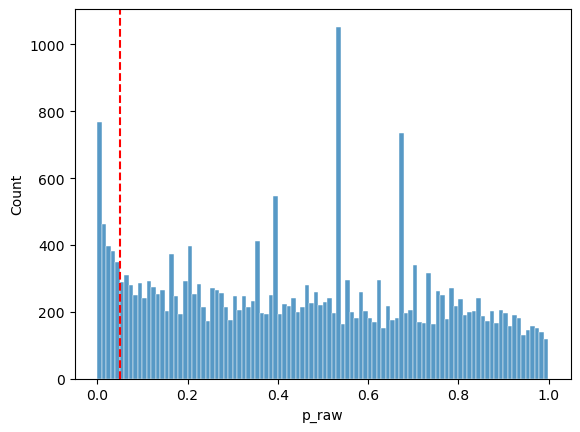

In [238]:
ax = sns.histplot(results_2['p_raw'], bins=100, edgecolor='white');
ax.axvline(0.05, color='red', linestyle='--');

In [239]:
cleaned_2.head(8)

,gene_id,dex,cell_line,count
0,ENSG00000000003,untreated,SRR1039508,679
2,ENSG00000000419,untreated,SRR1039508,467
3,ENSG00000000457,untreated,SRR1039508,260
4,ENSG00000000460,untreated,SRR1039508,60
6,ENSG00000000971,untreated,SRR1039508,3251
7,ENSG00000001036,untreated,SRR1039508,1433
8,ENSG00000001084,untreated,SRR1039508,519
9,ENSG00000001167,untreated,SRR1039508,394


In [ ]:
# Sort by gene_id then dex then cell_line
cleaned_3 = cleaned_2.sort_values(['gene_id', 'dex', 'cell_line']).reset_index(drop=True)

# remove characters from gene_id and cell_line that occur in all values
# this will reduce the size of the csv file
cleaned_3['gene_id'] = 'E' + cleaned_3['gene_id'].str[-6:]
cleaned_3['cell_line'] = 'S' + cleaned_3['cell_line'].str[-2:]

cleaned_3.head(16)

,gene_id,dex,cell_line,count
0,E000003,treated,S09,448
1,E000003,treated,S13,408
2,E000003,treated,S17,1047
3,E000003,treated,S21,572
4,E000003,untreated,S08,679
5,E000003,untreated,S12,873
6,E000003,untreated,S16,1138
7,E000003,untreated,S20,770
8,E000419,treated,S09,515
9,E000419,treated,S13,365


In [ ]:
# save cleaned dataset to a new csv file
cleaned_3.to_csv('../Datasets/airway_merged_data_cleaned.csv', index=False)